# Fixed Income Risk Dashboard
### Task 04 · Incident Forensics & Risk Controls

**RiskHub Python Lab | Market Data Quality | Trade Booking Controls | P&L Surveillance | VaR Remediation**

> **Business question:** Can the rates desk identify suspicious market-data and booking conditions, investigate mismatches between risk and P&L systems, and quantify how confirmed corrections affect reported risk?

### Executive snapshot · 2024 review

| Reporting mornings | Retrospective cases | Scaled P&L alert days | Fully corrected year-end VaR |
|:--|--:|--:|--:|
| **260** | **6** | **34** | **USD 1.460M** |

This module moves from **risk reporting (Task 1)**, **risk attribution (Task 2)** and **P&L explanation (Task 3)** to **detection and investigation**. It implements five independently defined screens, evaluates them against a post-year-end operations log, and remeasures year-end Historical VaR after authorized reference-data and position corrections.

**Architecture:** Python / NumPy / pandas / Matplotlib → JSON snapshot → C# / .NET 10 / ClosedXML → Excel investigation dashboard.

**Scope:** Educational simulated government-bond desk. The incidents are exercise labels, not evidence of actual market misconduct or production failures.


## 01 · Investigation workflow & information boundaries

The key design rule is **do not let hindsight contaminate the detection screen**.

| Stage | Available information | Output |
|:--|:--|:--|
| **1. Screen** | As-received zero curves, contemporaneously booked trades, reported P&L | Five alert types by date |
| **2. Investigate** | Exception dates, affected tenors/tickets, implied risk mismatch | Evidence and root-cause hypotheses |
| **3. Evaluate retrospectively** | Operations incident log, missing tickets, vendor corrections | Detection timing and correction impact |

The `INCIDENT_LOG`, `MISSING_TICKETS`, and `CORRECTIONS` objects below are **post-investigation reference data**. They are loaded later in the notebook, after the initial screens have been calculated. They are never used to decide which mornings trigger an alert.

### Signals in scope

- `PNL_FIXED`: unexplained P&L compared with a fixed 2023-calibrated threshold.
- `PNL_SCALED`: unexplained P&L normalized by contemporaneous interest-rate exposure.
- `STALE`: consecutive near-zero movements in a market-data vertex.
- `KINK`: abnormal change in one vertex relative to neighboring maturities.
- `LATE`: a trade entered into the risk blotter after its trade date.


## 02 · Market data, bonds & trade blotter

The dataset contains daily continuously compounded zero yields across **11 maturity vertices (3M–30Y)**, a government-bond universe of **19 instruments**, and a versioned ticket blotter with later amendments replacing earlier ticket values. P&L is externally reported, rather than derived from the risk engine.

The data loader searches upward from the working directory for `DataSource/rates_desk_feed.csv`. An explicit `RAD_RISK_ROOT` environment variable can override that search. This supports running the notebook from its own Task 4 folder.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Input configuration
import os
from pathlib import Path

if os.environ.get("RAD_RISK_ROOT"):
    PROJECT_ROOT = Path(os.environ["RAD_RISK_ROOT"]).expanduser().resolve()
else:
    here = Path.cwd().resolve()
    PROJECT_ROOT = next(
        (p for p in (here, *here.parents)
         if (p / "DataSource" / "rates_desk_feed.csv").is_file()),
        None
    )
    if PROJECT_ROOT is None:
        raise FileNotFoundError(
            "DataSource/rates_desk_feed.csv not found; set RAD_RISK_ROOT."
        )

DATA_FILE = PROJECT_ROOT / "DataSource" / "rates_desk_feed.csv"
df = pd.read_csv(DATA_FILE, parse_dates=["date"], index_col="date")
DATES = df.index                                   # business days 2020-12-31 .. 2024-12-31
LAB = [c[2:] for c in df.columns if c.startswith('Z_')]          # '3M', '6M', ..., '30Y'
TEN = np.array([0.25, 0.5, 1, 2, 3, 5, 7, 10, 15, 20, 30])       # years of the Z_ columns: the curve's VERTICES
Z = df[['Z_' + x for x in LAB]].to_numpy()         # the curve FEED as received: zero yields, %, continuously compounded
PNL = df['PNL_REPORTED'].to_numpy()                # the P&L system's daily desk P&L, USD (NaN before 2023-01-03)
REP = np.where(DATES >= '2023-01-03')[0]           # report mornings: every day with a reported P&L
BONDS = {   # bond: (coupon % a year, paid twice a year, maturity date)
    'GOV_23': (0.875, '2023-09-30'), 'GOV_24': (1.500, '2024-05-15'), 'GOV_25': (2.750, '2025-08-15'),
    'GOV_26': (4.125, '2026-06-15'), 'GOV_27': (3.250, '2027-11-15'), 'GOV_27B': (4.500, '2027-05-15'),
    'GOV_28': (4.000, '2028-05-15'), 'GOV_29': (3.750, '2029-02-15'), 'GOV_29B': (4.000, '2029-08-15'),
    'GOV_30': (4.000, '2030-02-15'), 'GOV_31': (4.125, '2031-08-15'), 'GOV_32': (2.875, '2032-05-15'),
    'GOV_33': (3.500, '2033-02-15'), 'GOV_34': (4.250, '2034-02-15'), 'GOV_37': (4.000, '2037-11-15'),
    'GOV_42': (3.250, '2042-08-15'), 'GOV_44': (4.375, '2044-02-15'), 'GOV_52': (3.000, '2052-08-15'),
    'GOV_53': (4.125, '2053-08-15'),
}
IDS = list(BONDS)
BLOTTER = [   # the risk system's trade blotter: (ticket, booked, traded, bond, face USD m: + bought / - sold)
    ('T001', '2022-12-30', '2022-12-30', 'GOV_23', 70), ('T002', '2022-12-30', '2022-12-30', 'GOV_24', 60),
    ('T003', '2022-12-30', '2022-12-30', 'GOV_25', 80), ('T004', '2022-12-30', '2022-12-30', 'GOV_27', 150),
    ('T005', '2022-12-30', '2022-12-30', 'GOV_29', 90), ('T006', '2022-12-30', '2022-12-30', 'GOV_32', -120),
    ('T007', '2022-12-30', '2022-12-30', 'GOV_33', -60), ('T008', '2022-12-30', '2022-12-30', 'GOV_37', 40),
    ('T009', '2022-12-30', '2022-12-30', 'GOV_42', -50), ('T010', '2022-12-30', '2022-12-30', 'GOV_52', 35),
    ('T011', '2023-02-14', '2023-02-14', 'GOV_26', 50), ('T012', '2023-04-20', '2023-04-20', 'GOV_32', 40),
    ('T013', '2023-06-07', '2023-06-07', 'GOV_30', 70), ('T014', '2023-08-23', '2023-08-23', 'GOV_44', -30),
    ('T015', '2023-10-11', '2023-10-11', 'GOV_27', -50), ('T016', '2023-11-29', '2023-11-29', 'GOV_53', 25),
    ('T017', '2024-01-17', '2024-01-17', 'GOV_25', -40), ('T018', '2024-02-21', '2024-02-21', 'GOV_30', 30),
    ('T019', '2024-04-10', '2024-04-10', 'GOV_34', 50), ('T019', '2024-04-16', '2024-04-10', 'GOV_34', -50),
    ('T020', '2024-05-22', '2024-05-22', 'GOV_42', 20),
    ('T021', '2024-06-12', '2024-06-12', 'GOV_27B', 40), ('T021', '2024-06-26', '2024-06-12', 'GOV_27B', 4),
    ('T022', '2024-08-07', '2024-08-07', 'GOV_44', 15),
    ('T026', '2024-08-21', '2024-08-21', 'GOV_28', 260), ('T027', '2024-08-21', '2024-08-21', 'GOV_31', -170),
    ('T023', '2024-09-12', '2024-09-09', 'GOV_29B', 8),
    ('T025', '2024-12-04', '2024-12-04', 'GOV_26', -20),
]   # a ticket that appears twice was AMENDED: its later row replaces the earlier one from that booked date
VAR_DAYS, VAR_K = 500, 5    # 1-day 99% HS VaR: the 5th worst of the last 500 daily curve moves (1% of 500)


## 03 · Shared valuation & exposure engine

To compare as-received and corrected books on the same basis, Task 4 reuses the Task 1–3 model conventions:

- Semiannual fixed-coupon cash flows, principal repayment at maturity.
- Continuously compounded zero-rate discounting and maturity-weighted interpolation.
- Bond-level valuation and 11-vertex Key-Rate DV01 from the same pricing inputs.
- Position history reconstructed from the latest available ticket amendment **by booked date**.

The value arrays `V`, `VA`, `K`, `KA`, and `CASH` are calculated by `history()`. Face amounts are in USD millions, so the existing `UNIT = 1e4` conversion maps face-million times price-per-100 into USD.


In [2]:
def cash_flows(bond):
    """the bond's payment dates after the data starts (every 6 months back from maturity, unadjusted)
    and its payments per 100 face: coupon / 2 on each date, + 100 at maturity."""
    cpn, mat = BONDS[bond]
    mat = pd.Timestamp(mat)
    dates = pd.DatetimeIndex([mat - pd.DateOffset(months=6 * k) for k in range(80)][::-1])
    dates = dates[dates > DATES[0]]
    cf = np.full(len(dates), cpn / 2)
    cf[-1] += 100.0
    return dates, cf


def interp_weights(tau):
    """weights W (shape tau.shape + (11,)) with W @ curve = the zero rate at each tau, linear between
    vertices and flat beyond the first and last. Each row has at most two non-zero weights, summing to 1."""
    tc = np.clip(tau, TEN[0], TEN[-1])
    j = np.clip(np.searchsorted(TEN, tc, side='right') - 1, 0, len(TEN) - 2)
    a = (tc - TEN[j]) / (TEN[j + 1] - TEN[j])
    W = np.zeros(np.shape(tau) + (len(TEN),))
    np.put_along_axis(W, j[..., None], (1 - a)[..., None], axis=-1)
    W2 = np.zeros_like(W)
    np.put_along_axis(W2, (j + 1)[..., None], a[..., None], axis=-1)
    return W + W2


def positions_history(blotter=BLOTTER):
    """Done for you (Task 1's book_on, for every day at once): the position in each bond (days x bonds, USD m
    face) at each close. Each blotter row changes its ticket's face from that row's booked date onwards."""
    b = pd.DataFrame(blotter, columns=['ticket', 'booked', 'traded', 'bond', 'face'])
    step = b['face'] - b.groupby('ticket')['face'].shift(1).fillna(0)
    Q = np.zeros((len(DATES), len(IDS)))
    for r, bond, s in zip(DATES.searchsorted(pd.to_datetime(b['booked'])), b['bond'], step):
        Q[r:, IDS.index(bond)] += s
    return Q


def history(curves):
    """Done for you (Task 1's price_and_ladder, for every day and bond at once). Per 100 face, rows = days, columns =
    bonds: V = value off curve t on day t; VA = value off curve t-1 on day t (the bond one day OLDER, on YESTERDAY's
    curve); K, KA = the key-rate ladders of the same two (days x bonds x 11); CASH = what the bond paid in (t-1, t]."""
    prev = np.vstack([curves[:1], curves[:-1]])
    out = {k: [] for k in ('V', 'VA', 'K', 'KA', 'CASH')}
    for bond in IDS:
        dates, cf = cash_flows(bond)
        tau = (dates.values[None, :] - DATES.values[:, None]) / np.timedelta64(1, 'D') / 365.0
        live = tau > 0
        W = interp_weights(np.where(live, tau, 1.0))
        for name, C in (('', curves), ('A', prev)):
            dfac = np.where(live, np.exp(-np.einsum('nmk,nk->nm', W, C) / 100 * tau), 0.0)
            out['V' + name].append(dfac @ cf)
            out['K' + name].append(np.einsum('nm,nmk->nk', dfac * cf * tau, W) * 1e-4)
        paid = (dates.values[None, :] > DATES.values[:-1, None]) & (dates.values[None, :] <= DATES.values[1:, None])
        out['CASH'].append(np.concatenate([[0.0], paid.astype(float) @ cf]))
    return {k: np.stack(v, axis=1) for k, v in out.items()}


UNIT = 1e4    # USD per (USD m face x price per 100): a position's USD value = face x UNIT x value per 100


## 04 · Five prospective detection screens

Each screen below is deliberately simple, transparent, and auditable. **An alert identifies a review candidate; it does not confirm that an error occurred.**

### 04.1 Stale market-data vertices

A vertex is flagged when its absolute day-over-day change is below **0.0002 percentage points (0.02 bp)** for at least **three consecutive report mornings**.

$$
|Z_{t,k}-Z_{t-1,k}| < 0.0002 \text{ percentage points}
$$

The earliest alert is the third consecutive near-zero-move morning. The implementation returns the complete run and later maps its first eligible alert date to the screening calendar.


In [3]:
def stale_runs(curves, tol=0.0002, min_len=3):
    """Feed screen 1: runs of at least `min_len` consecutive mornings on which a vertex moved by less than `tol`
    (in %, so 0.0002 = 0.02bp). Returns a list of (vertex label, first morning, last morning, length).
    Walk down each column of np.diff(curves, axis=0) counting the current run of tiny moves."""
    runs = []
    tiny = np.abs(np.diff(curves, axis=0)) < tol

    for j, label in enumerate(LAB):
        start = None

        for t in range(1, len(curves)):
            if tiny[t - 1, j]:
                if start is None:
                    start = t
            elif start is not None:
                length = t - start
                if length >= min_len:
                    runs.append((
                        label, DATES[start], DATES[t - 1], length
                    ))
                start = None

        if start is not None:
            length = len(curves) - start
            if length >= min_len:
                runs.append((
                    label, DATES[start], DATES[-1], length
                ))

    return runs


### 04.2 Isolated yield-curve kink jumps

For an interior tenor, compare the reported yield with a maturity-weighted interpolation of its immediate neighbors. A sudden change in that gap can reveal a suspicious isolated print.

$$
\kappa_{t,k}=Z_{t,k}-\left[(1-w_k)Z_{t,k-1}+w_k Z_{t,k+1}\right]
$$

$$
w_k=\frac{T_k-T_{k-1}}{T_{k+1}-T_{k-1}}
$$

A vertex-level observation is flagged when its day-over-day kink change exceeds **8 bp** in absolute value. Multiple vertices can fire on the same date; **vertex jumps and flagged dates are different counts**.


In [4]:
def kink_jumps(curves, limit_bp=8.0):
    """Feed screen 2: days on which an inner vertex jumped AWAY from its neighbours. kink = the vertex minus the
    straight line between its two neighbours (weights by maturity); flag every (day, vertex, change in bp) where
    the kink moved by more than `limit_bp` in one day. A true curve move shifts neighbours together; a bad print
    moves one point."""
    jumps = []

    for j in range(1, len(TEN) - 1):
        weight = (
            (TEN[j] - TEN[j - 1])
            / (TEN[j + 1] - TEN[j - 1])
        )

        interpolated = (
            curves[:, j - 1] * (1 - weight)
            + curves[:, j + 1] * weight
        )

        kink = curves[:, j] - interpolated
        changes_bp = np.diff(kink) * 100

        for t in np.where(np.abs(changes_bp) > limit_bp)[0]:
            jumps.append((
                DATES[t + 1],
                LAB[j],
                float(changes_bp[t])
            ))

    return sorted(jumps, key=lambda x: x[0])


### 04.3 Late-booked trades

Compare each ticket's **first** booking timestamp to its trade date. The number of delayed business days is computed with `numpy.busday_count`.

This screen detects observable late entries, but cannot independently find a trade that never appears in the received blotter.


In [5]:
def late_bookings(blotter=BLOTTER):
    """Walk screen: tickets whose FIRST row was booked after the trade date (the trade was live before the risk
    system knew). Returns a DataFrame of ticket, traded, booked, bond, face, lag (business days)."""
    b = pd.DataFrame(
        blotter,
        columns=['ticket', 'booked', 'traded', 'bond', 'face']
    )

    b = b.drop_duplicates('ticket', keep='first').copy()

    b['booked'] = pd.to_datetime(b['booked'])
    b['traded'] = pd.to_datetime(b['traded'])

    late = b[b['booked'] > b['traded']].copy()

    late['lag'] = np.busday_count(
        late['traded'].values.astype('datetime64[D]'),
        late['booked'].values.astype('datetime64[D]')
    )

    return late[
        ['ticket', 'traded', 'booked', 'bond', 'face', 'lag']
    ].reset_index(drop=True)


### 04.4 P&L exception screens and implied DV01

The fixed and scaled P&L flags reuse the Task 3 model. The risk system predicts first-order market P&L from the previous-day DV01 ladder plus carry; the remaining gap is `U`.

$$
U_t=\mathrm{ReportedPnL}_t-\left(\mathrm{Carry}_t-\sum_{k=1}^{11} L_{t-1,k}\,\Delta y_{t,k}\right)
$$

The normalized screen is calibrated on **2023 only** and applied to 2024, avoiding an in-period refit. Its scale grows with the squared norm of the prior-day key-rate ladder.

$$
\sigma_{U,t}=\sqrt{2}\,s\,\sqrt{\sum_k L_{t-1,k}^{2}},\qquad
z_t=\frac{U_t}{\sigma_{U,t}}
$$

**Fixed rule:** absolute unexplained P&L greater than 3.5 times its 2023 standard deviation. **Scaled rule:** absolute `z` greater than 3.5.

For subsequent forensic analysis, a *through-origin* regression against the average 11-vertex daily move estimates the risk exposure implied by unexplained P&L:

$$
\widehat{DV01}_{\mathrm{gap}}=-\frac{\sum_t U_t\,m_t}{\sum_t m_t^2},\qquad
m_t=\frac{1}{11}\sum_{k=1}^{11}\Delta y_{t,k}
$$

That estimate is a diagnostic approximation, not proof of a specific missing position.


In [6]:
def implied_dv01(U, moves, idx):
    """The DV01 the OTHER system holds and we do not, read off the unexplained P&L of mornings `idx`: regress U on
    the day's parallel move m (average of the 11 vertex moves, bp) through zero: -sum(U m) / sum(m^2)."""
    m = moves[idx].mean(axis=1)

    numerator = np.sum(U[idx] * m)
    denominator = np.sum(m ** 2)

    if denominator == 0:
        return np.nan

    return -float(numerator / denominator)


## 05 · Run the prospective screens

All five flags are constructed exclusively from the **as-received** feed, as-booked blotter, and P&L residual. This is the distinction between screening and the retrospective evaluation that follows.

The `flag` matrix contains one Boolean row per 2024 report morning. A stale run is marked on its first eligible confirmation date; kink dates and late-booking dates follow the corresponding feed and blotter observations.


In [7]:
# ---------------------------------------------------------------------------
H = history(Z)
Q = positions_history() * UNIT
moves = np.vstack([np.zeros((1, 11)), np.diff(Z, axis=0) * 100])
checks = [('stale_runs', lambda: stale_runs(Z[:40])), ('kink_jumps', lambda: kink_jumps(Z[:40])),
          ('late_bookings', lambda: late_bookings()), ('implied_dv01', lambda: implied_dv01(np.ones(10), moves, np.arange(1, 6)))]
todo = next((name for name, f in checks if f() is None), None)

if todo is not None:
    raise RuntimeError(f"Complete the model function: {todo}")

Qp = np.vstack([Q[:1], Q[:-1]])
L_prev = np.einsum('nb,nbk->nk', Qp, np.vstack([H['K'][:1], H['K'][:-1]]))
c = (Qp * (H['VA'] + H['CASH'] - np.vstack([H['V'][:1], H['V'][:-1]]))).sum(1)
U = PNL - c + (L_prev * moves).sum(1)                       # Task 3's unexplained P&L
g2 = np.sqrt((L_prev ** 2).sum(1))
y23, y24 = REP[DATES[REP].year == 2023], REP[DATES[REP].year == 2024]
s = float(np.std(U[y23]) / np.sqrt(2 * np.mean(g2[y23] ** 2)))
z = U / (np.sqrt(2) * s * g2)                                 # Task 3's z, noise model fitted on 2023
days24 = DATES[y24]
flag = pd.DataFrame(False, index=days24, columns=['PNL_FIXED', 'PNL_SCALED', 'STALE', 'KINK', 'LATE'])
flag['PNL_FIXED'] = np.abs(U[y24]) > 3.5 * np.std(U[y23])
flag['PNL_SCALED'] = np.abs(z[y24]) > 3.5
st, kj, lb = stale_runs(Z), kink_jumps(Z), late_bookings()


In [8]:
print("Feed screen 1, stale runs (3+ mornings with a move under 0.02bp):")
for lbl, a, b, n_ in st:
    print(f"  {lbl}: {a.date()} to {b.date()} ({n_} mornings)")
    flag.loc[days24[days24.searchsorted(a) + 2] if a.year == 2024 else days24[0], 'STALE'] = True  # flags on its 3rd morning
print(f"Feed screen 2, kink jumps over 8bp: {len(kj)}")
for day, lbl, ch in kj:
    print(f"  {day.date()} {lbl} {ch:+.1f}bp")
    if day in flag.index:
        flag.loc[day, 'KINK'] = True
print("Walk screen, late bookings:")
print(lb.to_string(index=False))
for _, r in lb.iterrows():
    if pd.Timestamp(r.booked) in flag.index:
        flag.loc[pd.Timestamp(r.booked), 'LATE'] = True


Feed screen 1, stale runs (3+ mornings with a move under 0.02bp):
  1Y: 2024-07-16 to 2024-07-25 (8 mornings)
Feed screen 2, kink jumps over 8bp: 6
  2024-11-20 3Y -10.4bp
  2024-11-20 5Y +28.5bp
  2024-11-20 7Y -16.0bp
  2024-11-21 3Y +10.1bp
  2024-11-21 5Y -29.9bp
  2024-11-21 7Y +16.1bp
Walk screen, late bookings:
ticket     traded     booked    bond  face  lag
  T023 2024-09-09 2024-09-12 GOV_29B     8    3


### 05.1 What the screens observed

| Screen | 2024 alert mornings | Interpretation |
|:--|--:|:--|
| `PNL_FIXED` | **49** | Fixed-size unexplained P&L threshold |
| `PNL_SCALED` | **34** | Risk-normalized unexplained P&L threshold |
| `STALE` | **1** | One confirmed stale-run alert date |
| `KINK` | **2** | Two dates, covering **6 vertex-level jumps** |
| `LATE` | **1** | One late-booked ticket (`T023`) |

The stale screen finds an eight-morning freeze in the **1Y** zero yield from **July 16–25, 2024** and first alerts on **July 18**. The kink screen identifies abnormal **3Y, 5Y and 7Y** movements on **November 20 and 21**. The late-booking screen identifies `T023`: traded **September 9**, booked **September 12**, a **three-business-day** delay.

These counts are **signals**, not six independently confirmed incident diagnoses. The six confirmed cases enter only in the evaluation section below.


## 06 · Retrospective case register (evaluation only)

After the year-end review, operations documented **six cases**. Their descriptions, incident windows, omitted ticket and corrected vendor quotes are not available to the earlier screening engine.

| Case | Type | Investigation focus |
|:--|:--|:--|
| I1 | `WRONG_SIDE` | `T019`: GOV_34 side reversed before amendment |
| I2 | `NOTIONAL` | `T021`: GOV_27B face amount overstated |
| I3 | `LATE` | `T023`: booked after trade date |
| I4 | `MISSED` | `T024`: GOV_33 buyback omitted entirely |
| I5 | `STALE` | Eight consecutive stale 1Y market-data mornings |
| I6 | `BAD_PRINT` | 5Y isolated erroneous market quote |

The operations log is a *grading/reference key* for retrospectively describing screening coverage and correction effects. It must not be interpreted as data available to the desk in real time.


In [9]:
INCIDENT_LOG = [   # the operations review of 2024, written after year-end: the GRADING KEY, never an input to a screen
    # first / last = the report mornings the incident could show on (a booking error held overnight from day s shows
    # in the P&L of morning s + 1 onwards; a feed fault shows on its own mornings)
    {'id': 'I1', 'kind': 'WRONG_SIDE', 'first': '2024-04-11', 'last': '2024-04-16', 'bond': 'GOV_34', 'error_m': +100,
     'what': 'T019 was a SALE of 50m GOV_34, booked as a purchase; amended 2024-04-16'},
    {'id': 'I2', 'kind': 'NOTIONAL', 'first': '2024-06-13', 'last': '2024-06-26', 'bond': 'GOV_27B', 'error_m': +36,
     'what': 'T021 bought 4m GOV_27B, booked as 40m; amended 2024-06-26'},
    {'id': 'I3', 'kind': 'LATE', 'first': '2024-09-10', 'last': '2024-09-12', 'bond': 'GOV_29B', 'error_m': -8,
     'what': 'T023 bought 8m GOV_29B on 2024-09-09, booked 2024-09-12'},
    {'id': 'I4', 'kind': 'MISSED', 'first': '2024-10-16', 'last': '2024-12-31', 'bond': 'GOV_33', 'error_m': -60,
     'what': 'T024 bought back 60m GOV_33 (closing the short) on 2024-10-15; never reached the risk system'},
    {'id': 'I5', 'kind': 'STALE', 'first': '2024-07-16', 'last': '2024-07-26', 'bond': None, 'error_m': 0,
     'what': 'Z_1Y frozen at its 2024-07-15 value on 8 mornings, 2024-07-16 to 2024-07-25'},
    {'id': 'I6', 'kind': 'BAD_PRINT', 'first': '2024-11-20', 'last': '2024-11-21', 'bond': None, 'error_m': 0,
     'what': 'Z_5Y printed 31bp too high on 2024-11-20 only'},
]   # error_m = booked minus true position, USD m face, while the incident lasts
MISSING_TICKETS = [('T024', '2024-10-15', '2024-10-15', 'GOV_33', 60)]
CORRECTIONS = {   # the vendor's corrected values for the faulty feed points: (date, column): zero yield %
    ('2024-07-16', 'Z_1Y'): 4.7904, ('2024-07-17', 'Z_1Y'): 4.7981, ('2024-07-18', 'Z_1Y'): 4.7587,
    ('2024-07-19', 'Z_1Y'): 4.7402, ('2024-07-22', 'Z_1Y'): 4.6895, ('2024-07-23', 'Z_1Y'): 4.6907,
    ('2024-07-24', 'Z_1Y'): 4.6368, ('2024-07-25', 'Z_1Y'): 4.7069, ('2024-11-20', 'Z_5Y'): 4.4186,
}


def corrected_blotter():
    """every ticket as finally amended, effective from its TRADED date, plus the tickets the risk
    system never received. This is the true book."""
    last = {}
    for row in BLOTTER + MISSING_TICKETS:
        last[row[0]] = row
    return [(t, traded, traded, bond, face) for (t, booked, traded, bond, face) in last.values()]


def corrected_feed():
    """the curve feed with the vendor's corrections applied."""
    Zc = Z.copy()
    for (day, col), v in CORRECTIONS.items():
        Zc[DATES.get_loc(pd.Timestamp(day)), LAB.index(col[2:])] = v
    return Zc


### 06.1 First-hit timing and clean-morning review

The evaluation intersects each screen's flagged dates with each incident's retrospective active window. It records the **first matching alert** and the number of **report mornings elapsed** since the incident window began.

The printed "no incident live" count means *no case in this six-case reference log was active on that date*. It is not necessarily a verified real-world false positive, because the simulated case log is limited to these six events.


In [10]:
print("\nEach incident in the operations log against each screen (first morning it fired, mornings of delay):")
live = pd.Series(False, index=days24)
print(f"  {'id':<4}{'kind':<11}{'mornings':>9}  " + ''.join(f"{k:>13}" for k in flag.columns))
for inc in INCIDENT_LOG:
    win = (days24 >= inc['first']) & (days24 <= inc['last'])
    live |= win
    cells = []
    for k in flag.columns:
        hit = np.where(flag[k].to_numpy() & win)[0]
        w0 = np.where(win)[0][0]
        cells.append(f"{str(days24[hit[0]].date())[5:]} +{hit[0] - w0}" if len(hit) else '-')
    print(f"  {inc['id']:<4}{inc['kind']:<11}{win.sum():>9}  " + ''.join(f"{x:>13}" for x in cells))
for k in flag.columns:
    print(f"  {k:<11} red on {flag[k].sum():>3} mornings of 2024, {(flag[k] & ~live).sum():>3} of them with no incident live")



Each incident in the operations log against each screen (first morning it fired, mornings of delay):
  id  kind        mornings      PNL_FIXED   PNL_SCALED        STALE         KINK         LATE
  I1  WRONG_SIDE         4       04-11 +0     04-11 +0            -            -            -
  I2  NOTIONAL          10       06-13 +0     06-13 +0            -            -            -
  I3  LATE               3              -            -            -            -     09-12 +2
  I4  MISSED            54       10-16 +0     10-16 +0            -    11-20 +25            -
  I5  STALE              9              -            -     07-18 +2            -            -
  I6  BAD_PRINT          2       11-20 +0     11-20 +0            -     11-20 +0            -
  PNL_FIXED   red on  49 mornings of 2024,   4 of them with no incident live
  PNL_SCALED  red on  34 mornings of 2024,   0 of them with no incident live
  STALE       red on   1 mornings of 2024,   0 of them with no incident live
  KINK   

### 06.2 What the case study shows

- **I1 (wrong side)** and **I2 (notional)** both generate P&L exceptions on their first active report mornings.
- **I3 (late booking)** triggers the `LATE` control on **September 12**, two report mornings after the retrospective window begins. There was no earlier booking record for this screen to flag.
- **I4 (completely missed trade)** generates a P&L exception at the start of its case window, but the late-booking screen cannot detect the absent ticket.
- **I5 (stale quote)** is detected once the three-morning persistence requirement is met: **July 18**, a two-morning delay.
- **I6 (bad print)** produces P&L and kink signals on **November 20**. The neighbor-based kink logic also flags the reversal on November 21.

Across the 2024 test period, `PNL_FIXED` flags **four mornings outside the six logged windows**; `PNL_SCALED` flags **none** outside those windows. That observation is specific to this simulated record and chosen 3.5-sigma threshold; it does not establish out-of-sample precision.


## 07 · Diagnose booking mismatches with implied risk

An unexplained P&L residual that moves systematically with the parallel rate factor may indicate a DV01 gap between the independently calculated book and the external P&L system.

The regression estimate is compared with a **reference DV01 gap** computed from the retrospective face-amount error and the affected bond's historical risk. Disagreement is expected: the one-factor regression compresses an 11-vertex curve exposure into a single estimate and may include data/model noise.


In [11]:
print("\nImplied DV01 of the gap (the DV01 the P&L system holds and we do not) vs the log's error:")
for inc in INCIDENT_LOG:
    if not inc['bond']:
        continue
    idx = y24[(days24 >= inc['first']) & (days24 <= inc['last'])]
    b = IDS.index(inc['bond'])
    err = -inc['error_m'] * UNIT * H['K'][idx - 1, b].sum(1).mean()      # true minus booked, USD per bp
    print(f"  {inc['id']} {inc['kind']:<11} {len(idx):>3} mornings: implied {implied_dv01(U, moves, idx):>+10,.0f}"
          f"   log ({inc['error_m']:+d}m {inc['bond']}) {err:>+10,.0f}")



Implied DV01 of the gap (the DV01 the P&L system holds and we do not) vs the log's error:
  I1 WRONG_SIDE    4 mornings: implied    -69,937   log (+100m GOV_34)    -85,307
  I2 NOTIONAL     10 mornings: implied    -10,779   log (+36m GOV_27B)     -9,919
  I3 LATE          3 mornings: implied     +3,248   log (-8m GOV_29B)     +3,593
  I4 MISSED       54 mornings: implied    +31,668   log (-60m GOV_33)    +40,518


## 08 · Remediation impact: recompute year-end VaR

This is a **hindsight correction analysis**, not a live alert. The same 500-shock, fifth-worst Historical Simulation VaR engine is run three times:

| Scenario | 2024-12-31 VaR |
|:--|--:|
| As-received curve + as-booked positions | **USD 939,306** |
| Vendor-corrected curve + as-booked positions | **USD 939,137** |
| Vendor-corrected curve + corrected positions | **USD 1,460,314** |

The final figure is **USD 521,008 higher** than the original risk report, so the received result was approximately **35.7% below** the fully corrected VaR when expressed relative to the corrected value.

The limited feed-only difference is **not evidence that the bad print is harmless**. Historical Simulation VaR depends on the fifth-worst ordered scenario. In the original year-end window the November 20 bad-print scenario was the **second-worst**; changes to that extreme scenario need not change the fifth-worst threshold very much.


In [12]:
def var_today(curves, blotter):
    h = history(curves)
    lad = np.einsum('b,bk->k', positions_history(blotter)[-1] * UNIT, h['K'][-1])
    mv = np.diff(curves[-VAR_DAYS - 1:], axis=0) * 100
    return float(-np.sort(-mv @ lad)[VAR_K - 1])
Zc = corrected_feed()
v0, v1, v2 = var_today(Z, BLOTTER), var_today(Zc, BLOTTER), var_today(Zc, corrected_blotter())
print(f"\nVaR at the close of {DATES[-1].date()}: as received USD {v0:,.0f}; feed corrected USD {v1:,.0f}; "
      f"feed and book corrected USD {v2:,.0f} (the reported VaR was {100 * (1 - v0 / v2):.1f}% too low)")
lad = np.einsum('b,bk->k', Q[-1], H['K'][-1])
sc = pd.Series(-moves[-VAR_DAYS:] @ lad, index=DATES[-VAR_DAYS:]).sort_values()
p = pd.Timestamp('2024-11-20')
print(f"  the bad print's scenario ({p.date()}) is number {sc.index.get_loc(p) + 1} of {VAR_DAYS} in today's "
      f"window, P&L USD {sc[p]:+,.0f}; the 5th and 6th worst are USD {sc.iloc[4]:+,.0f} and {sc.iloc[5]:+,.0f}")



VaR at the close of 2024-12-31: as received USD 939,306; feed corrected USD 939,137; feed and book corrected USD 1,460,314 (the reported VaR was 35.7% too low)
  the bad print's scenario (2024-11-20) is number 2 of 500 in today's window, P&L USD -1,098,229; the 5th and 6th worst are USD -939,306 and -939,137


## 09 · Evidence timeline

The chart below overlays **prospective alert mornings** on **retrospective incident windows**. Shaded areas are shown for case-study interpretation only and are **not an input** to the alert-generation rules.

**Reading tip:** Red points represent P&L screens; blue points represent market-data and booking controls. One incident may trigger several screens, and one screen may fire more than once during an incident.


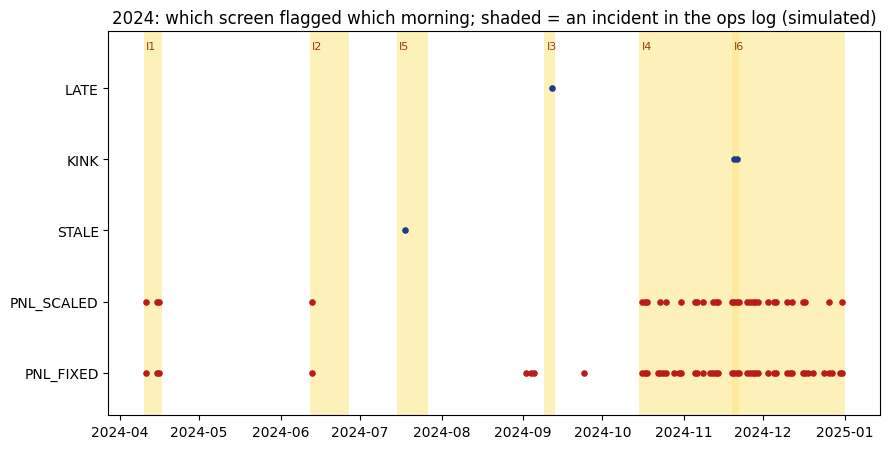

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.6))
y = {k: i for i, k in enumerate(flag.columns)}
for inc in INCIDENT_LOG:
    ax.axvspan(pd.Timestamp(inc['first']) - pd.Timedelta(days=1), pd.Timestamp(inc['last']) + pd.Timedelta(days=1),
               color='#fde68a', alpha=0.6, lw=0)
    ax.text(pd.Timestamp(inc['first']), len(y) - 0.45, inc['id'], fontsize=8, color='#92400e')
for k, i in y.items():
    d = flag.index[flag[k]]
    ax.scatter(d, np.full(len(d), i), s=14, color='#b91c1c' if k.startswith('PNL') else '#1e3a8a')
ax.set_yticks(list(y.values()))
ax.set_yticklabels(list(y.keys()))
ax.set_ylim(-0.6, len(y) - 0.2)
ax.set_title('2024: which screen flagged which morning; shaded = an incident in the ops log (simulated)')
plt.tight_layout()
plt.show()


## 10 · Python → JSON → C# / Excel reporting

The Python calculations feed a standalone C# Excel generator. This avoids reimplementing the risk methodology in workbook macros and keeps a documented data contract between analytics and presentation.

**Workbook delivered by `DeskRiskForensics_Task4.cs`:**

| Sheet | Analyst workflow |
|:--|:--|
| `01 Overview` | Detection counts and retrospective coverage |
| `02 Daily Screens` | All 260 report mornings and five screen flags |
| `03 Investigation` | Select a date and inspect contemporaneous evidence |
| `04 Evidence Register` | Stale runs, kink jumps and late tickets |
| `05 Case Review` | Post-review case labels and detection delays |
| `06 VaR Impact` | As-received versus corrected VaR |
| `07 Methodology` | Definitions, thresholds and interpretation limits |

The next cells export `task4_snapshot.json` to `Excel_Template_Output/`. That folder is intentionally ignored by Git; the notebooks and C# generator are the version-controlled deliverables.

### 10.1 Rebuild from the raw inputs

The exporter recalculates the screening inputs from the as-received data. Corrected curves and operations labels remain excluded from alert construction.


In [14]:
# TASK 4 | INCIDENT FORENSICS -> C# EXCEL SNAPSHOT
# Portfolio export section: runs after the detection and evaluation cells.
# Corrections and INCIDENT_LOG are used only for retrospective evaluation.

import base64
import io
import json
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the project root even when this notebook is in Task4_Incident_Forensics/.
if os.environ.get("RAD_RISK_ROOT"):
    PROJECT_ROOT = Path(os.environ["RAD_RISK_ROOT"]).expanduser().resolve()
else:
    current = Path.cwd().resolve()
    PROJECT_ROOT = next((p for p in (current, *current.parents)
                         if (p / "DataSource" / "rates_desk_feed.csv").is_file()), None)
    if PROJECT_ROOT is None:
        raise FileNotFoundError("Cannot locate DataSource/rates_desk_feed.csv. Set RAD_RISK_ROOT.")
OUTPUT_DIR = PROJECT_ROOT / "Excel_Template_Output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Recalculate from the uncorrected/raw feed; NEVER use incident labels or
# corrected values to build detection flags.
UNIT_LOCAL = 1e4
_H = history(Z)
_Q = positions_history() * UNIT_LOCAL
_moves = np.vstack((np.zeros((1, len(LAB))), np.diff(Z, axis=0) * 100.0))
_Qp = np.vstack((_Q[:1], _Q[:-1]))
_Lp = np.einsum("nb,nbk->nk", _Qp, np.vstack((_H["K"][:1], _H["K"][:-1])))
_prev_value = np.vstack((_H["V"][:1], _H["V"][:-1]))
_carry = (_Qp * (_H["VA"] + _H["CASH"] - _prev_value)).sum(axis=1)
_market = -(_Lp * _moves).sum(axis=1)
_predicted = _carry + _market
_U = PNL - _predicted
_risk_norm = np.sqrt((_Lp ** 2).sum(axis=1))
_y23 = REP[DATES[REP].year == 2023]
_y24 = REP[DATES[REP].year == 2024]
_noise_bp = float(np.std(_U[_y23]) / np.sqrt(2.0 * np.mean(_risk_norm[_y23] ** 2)))
_noise_sd = np.sqrt(2.0) * _noise_bp * _risk_norm
_z = np.divide(_U, _noise_sd, out=np.full_like(_U, np.nan), where=_noise_sd > 0)
_train_sd = float(np.std(_U[_y23]))
if not (_noise_bp > 0 and _train_sd > 0):
    raise ValueError("Invalid Task 3 noise model calibration.")


### 10.2 Encode five screening signals

One 2024 daily row contains the P&L residual, normalized score, independent screen flags and corresponding observable evidence. The stale trigger is stored on its **third consecutive tiny-move morning**.


In [15]:
# THE DETECTION SCREENS: operate only on what was known in the received feed
# and the contemporaneously booked blotter.
_stales = stale_runs(Z, tol=0.0002, min_len=3)
_kinks = kink_jumps(Z, limit_bp=8.0)
_lates = late_bookings(BLOTTER)
_days24 = pd.DatetimeIndex(DATES[_y24])
_flags = pd.DataFrame(False, index=_days24,
                      columns=["PNL_FIXED", "PNL_SCALED", "STALE", "KINK", "LATE"])
_flags["PNL_FIXED"] = np.abs(_U[_y24]) > (3.5 * _train_sd)
_flags["PNL_SCALED"] = np.abs(_z[_y24]) > 3.5
_stale_info = {day: [] for day in _days24}
_kink_info = {day: [] for day in _days24}
_late_info = {day: [] for day in _days24}

stale_events = []
for vertex, first, last, length in _stales:
    first, last = pd.Timestamp(first), pd.Timestamp(last)
    # Third *consecutive* tiny-move morning is the earliest possible alert.
    trigger_i = DATES.get_loc(first) + 2
    trigger = pd.Timestamp(DATES[trigger_i]) if trigger_i < len(DATES) else None
    if trigger is not None and trigger <= last and trigger in _flags.index:
        _flags.loc[trigger, "STALE"] = True
        _stale_info[trigger].append(vertex)
    stale_events.append({"vertex": vertex, "first": first.strftime("%Y-%m-%d"),
                         "last": last.strftime("%Y-%m-%d"), "length": int(length),
                         "alertDate": trigger.strftime("%Y-%m-%d") if trigger is not None and trigger <= last else None})

kink_events = []
for day, vertex, change in _kinks:
    day = pd.Timestamp(day)
    if day in _flags.index:
        _flags.loc[day, "KINK"] = True
        _kink_info[day].append(f"{vertex} {change:+.1f}bp")
    kink_events.append({"date": day.strftime("%Y-%m-%d"), "vertex": vertex,
                        "changeBp": float(change)})

late_events = []
for _, row in _lates.iterrows():
    trade_date = pd.Timestamp(row.traded)
    booked = pd.Timestamp(row.booked)
    if booked in _flags.index:
        _flags.loc[booked, "LATE"] = True
        _late_info[booked].append(str(row.ticket))
    late_events.append({"ticket": str(row.ticket), "traded": trade_date.strftime("%Y-%m-%d"),
                        "booked": booked.strftime("%Y-%m-%d"), "bond": str(row.bond),
                        "faceM": float(row.face), "lagBusinessDays": int(row.lag)})


### 10.3 Attach hindsight-only investigation records

The JSON keeps incident identifiers in fields explicitly labeled `EvaluationOnly`. The correct positioning of the evaluation data matters: an analyst may compare alerts with known outcomes, but those outcomes must never produce or tune the flags for the same sample.

The year-end correction bridge also stays in a separate section of the JSON.


In [16]:
# Retrospective evidence is stored separately from screen inputs.
incidents = []
for inc in INCIDENT_LOG:
    first = pd.Timestamp(inc["first"])
    last = pd.Timestamp(inc["last"])
    mask = (_days24 >= first) & (_days24 <= last)
    win_days = _days24[mask]
    hit_map = {}
    for screen in _flags.columns:
        hits = win_days[_flags.loc[win_days, screen].to_numpy()]
        hit_map[screen] = None
        if len(hits):
            hit_map[screen] = {"date": hits[0].strftime("%Y-%m-%d"),
                               "delayDays": int(np.where(win_days == hits[0])[0][0])}
    idx = _y24[mask]
    if inc["bond"] is not None:
        implied = float(implied_dv01(_U, _moves, idx))
        bond_i = IDS.index(inc["bond"])
        expected = float(-inc["error_m"] * UNIT_LOCAL * _H["K"][idx - 1, bond_i].sum(axis=1).mean())
    else:
        implied, expected = None, None
    incidents.append({"id": inc["id"], "kind": inc["kind"],
                      "first": first.strftime("%Y-%m-%d"), "last": last.strftime("%Y-%m-%d"),
                      "bond": inc["bond"], "errorM": float(inc["error_m"]),
                      "what": inc["what"], "days": int(len(win_days)),
                      "firstHits": hit_map, "impliedDv01": implied, "expectedDv01": expected})

# VaR correction bridge: hindsight only, never screen inputs.
def _closing_var(curves, blotter):
    hh = history(curves)
    qq = positions_history(blotter)[-1] * UNIT_LOCAL
    ladder = np.einsum("b,bk->k", qq, hh["K"][-1])
    mm = np.diff(curves[-VAR_DAYS-1:], axis=0) * 100
    pnl_scenarios = -mm @ ladder
    return float(-np.partition(pnl_scenarios, VAR_K-1)[VAR_K-1])

_Zc = corrected_feed()
_var_raw = _closing_var(Z, BLOTTER)
_var_feed = _closing_var(_Zc, BLOTTER)
_var_corrected = _closing_var(_Zc, corrected_blotter())
_current_ladder = np.einsum("b,bk->k", _Q[-1], _H["K"][-1])
_scenario_series = pd.Series(-_moves[-VAR_DAYS:] @ _current_ladder,
                            index=DATES[-VAR_DAYS:]).sort_values()
_bad_day = pd.Timestamp("2024-11-20")
_bad_rank = int(_scenario_series.index.get_loc(_bad_day) + 1)
_bad_scenario_pnl = float(_scenario_series.loc[_bad_day])

rows = []
for idx in _y24:
    date = pd.Timestamp(DATES[idx])
    known = [i["id"] for i in incidents
             if i["first"] <= date.strftime("%Y-%m-%d") <= i["last"]]
    row = {"date": date.strftime("%Y-%m-%d"),
           "reportedPnl": float(PNL[idx]), "predictedPnl": float(_predicted[idx]),
           "unexplained": float(_U[idx]), "zScore": float(_z[idx]),
           "flags": {key: bool(_flags.loc[date, key]) for key in _flags.columns},
           "staleEvidence": ", ".join(_stale_info[date]),
           "kinkEvidence": ", ".join(_kink_info[date]),
           "lateTickets": ", ".join(_late_info[date]),
           "incidentIdsEvaluationOnly": ", ".join(known)}
    if not all(np.isfinite(row[k]) for k in ["reportedPnl", "predictedPnl", "unexplained", "zScore"]):
        raise ValueError(f"Nonfinite metric on {date.date()}")
    rows.append(row)


### 10.4 Export audit-ready workbook data

The final JSON carries daily observations, evidence lists, retrospective case reviews and VaR remediation figures. The timeline is encoded as a static PNG for the C# presentation layer. The workbook's date selection remains interactive through Excel formulas.


In [17]:
# Chart: 2024 screening timeline; event shading is deliberately RETROSPECTIVE.
fig, ax = plt.subplots(figsize=(11.5, 3.5))
for e in incidents:
    ax.axvspan(pd.Timestamp(e["first"]), pd.Timestamp(e["last"]),
               color="#FDE68A", alpha=0.32, lw=0)
for screen_idx, screen in enumerate(_flags.columns):
    dates = _flags.index[_flags[screen].to_numpy()]
    ax.scatter(dates, np.full(len(dates), screen_idx), s=16,
               color="#B91C1C" if screen.startswith("PNL") else "#244767", zorder=3)
ax.set_yticks(range(len(_flags.columns)), list(_flags.columns))
ax.set_ylim(-0.6, len(_flags.columns) - 0.4)
ax.set_title("Task 4 / Daily raw-feed screening | shaded windows: retrospective incidents")
ax.grid(axis="x", alpha=0.12)
fig.tight_layout()
buffer = io.BytesIO()
fig.savefig(buffer, format="png", dpi=125, bbox_inches="tight", facecolor="white")
plt.close(fig)
chart = base64.b64encode(buffer.getvalue()).decode("ascii")

snapshot = {
    "asOf": str(_days24[-1].date()), "reportDays": len(rows), "fitNoiseBp": _noise_bp,
    "trainingStdUnexplained": _train_sd, "sigmaThreshold": 3.5,
    "staleTolerancePct": 0.0002, "staleMinDays": 3, "kinkLimitBp": 8.0,
    "daily": rows, "staleRuns": stale_events, "kinkJumps": kink_events,
    "lateBookings": late_events, "incidentsEvaluationOnly": incidents,
    "closingVar": {"asReceived": _var_raw, "feedCorrected": _var_feed,
                   "feedAndBookCorrected": _var_corrected},
    "badPrintScenario": {"date": str(_bad_day.date()), "rank": _bad_rank,
                         "pnl": _bad_scenario_pnl,
                         "fifthWorstPnl": float(_scenario_series.iloc[4]),
                         "sixthWorstPnl": float(_scenario_series.iloc[5])},
    "screenChart": chart,
}
# Existing 2024 Task 3 invariants remain intact.
assert len(rows) == len(_y24)
assert sum(x["flags"]["PNL_FIXED"] for x in rows) == 49
assert sum(x["flags"]["PNL_SCALED"] for x in rows) == 34
assert abs(_var_raw - _closing_var(Z, BLOTTER)) < 1e-8
out = OUTPUT_DIR / "task4_snapshot.json"
out.write_text(json.dumps(snapshot, allow_nan=False), encoding="utf-8")
print("Snapshot:", out)
print("2024 mornings:", len(rows), "incident cases:", len(incidents))
print("Screen counts:", {k: int(_flags[k].sum()) for k in _flags})
print("VaR raw / corrected:", f"{_var_raw:,.0f}", f"{_var_corrected:,.0f}")


Snapshot: /mnt/data/task4_portfolio_qa/Excel_Template_Output/task4_snapshot.json
2024 mornings: 260 incident cases: 6
Screen counts: {'PNL_FIXED': 49, 'PNL_SCALED': 34, 'STALE': 1, 'KINK': 2, 'LATE': 1}
VaR raw / corrected: 939,306 1,460,314


### 10.5 Generate Excel on a machine with .NET 10

The code below calls the separate C# source. It uses the already-discovered `PROJECT_ROOT` and is **optional on machines without the .NET SDK or C# generator source**. The published notebook can therefore be inspected and its Python analytics rerun independently of the Excel build step.


In [18]:
import subprocess
import shutil

CS_FILE = PROJECT_ROOT / "Excel_Template_Design" / "DeskRiskForensics_Task4.cs"

if not CS_FILE.is_file():
    print(f"Excel generation skipped: source not found at {CS_FILE}")
elif shutil.which("dotnet") is None:
    print("Excel generation skipped: .NET SDK not installed.")
else:
    result = subprocess.run(
        ["dotnet", "run", "--file", str(CS_FILE)],
        cwd=PROJECT_ROOT,
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace",
    )
    print("Exit Code:", result.returncode)
    print(result.stdout)
    print(result.stderr)
    if result.returncode != 0:
        raise RuntimeError("Task 4 C# Excel generation failed.")


Exit Code: 0
SUCCESS: Task 4 workbook generated
Excel: C:\Users\franklinpeng\Desktop\RDA Risk test\Excel_Template_Output\RatesDesk_IncidentForensics_Task4_2024-12-31.xlsx
Report days: 260 | Evaluation cases: 6
Fixed / Scaled / Stale / Kink / Late: 49 / 34 / 1 / 2 / 1
VaR: received USD 939,306 -> corrected USD 1,460,314




## 11 · Controls, limitations & interpretation

**Reproducibility controls:**

- The original feed and booked positions determine every prospective flag; the exporter repeats this computation before writing the JSON.
- The 2023 calibration sample is fixed before 2024 screening.
- Fixed / scaled alert-day counts are asserted against the expected **49 / 34** results.
- 500 historical curve moves and the fifth-worst loss consistently define closing 99% VaR.
- The 2024 incident list and corrected reference data are stored only in hindsight-oriented outputs.

**Limitations:** The fixed and scaled screens are heuristic thresholds, not independently validated statistical error classifiers. A completely omitted trade cannot be found through the late-booking rule alone. The kink rule can respond to genuine localized curve changes. The implied-DV01 regression compresses term-structure risk into a parallel-factor proxy. Historical VaR uses linear DV01 P&L and excludes liquidity, credit spread, convexity and funding effects.

### Desk takeaway

> A defensible operational-control workflow separates **what the system could have known**, **what it flagged**, **what investigators subsequently learned**, and **how confirmed repairs changed risk**.

**Next module — Task 5:** compare alternative screen policies on injected incidents, impose clean-day budgets and detection-delay constraints, then select a review policy without retrofitting it to individual case outcomes.

---

*Educational risk-engineering portfolio derived from the RiskHub Fixed Income Risk Dashboard lab; simulated market and trade data, not a production surveillance or trading-control system.*
